# Задание 5. Исследовательский анализ SMS-данных (EDA)

Анализ выполняется на всём очищенном наборе **до** разбиения и обучения. Никакие параметры здесь не подбираются, поэтому утечки данных нет.

Чтобы запустить ноутбук, сначала выполните `python -m ml.data.load_sms` и `python -m ml.data.clean_sms`.

In [1]:
import re
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().resolve()
ROOT = ROOT if (ROOT / "manage.py").exists() else ROOT.parent
sys.path.insert(0, str(ROOT))

from ml.preprocessing import STOPWORDS

FIGURES = ROOT / "docs" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

HAM_COLOR, SPAM_COLOR = "#2a78d6", "#eb6834"
NAMES = {0: "Безопасное (ham)", 1: "Мошенничество (spam)"}
COLORS = {0: HAM_COLOR, 1: SPAM_COLOR}

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#8a8986",
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8, "axes.axisbelow": True,
})


def save(fig, name):
    fig.savefig(FIGURES / name, dpi=170, bbox_inches="tight", facecolor="white")


df = pd.read_csv(ROOT / "data" / "processed" / "sms_clean.csv", encoding="utf-8", keep_default_na=False)
print(f"Записей: {len(df)}")
df.head(3)

Записей: 5137


,id,text_raw,text_clean,label
0,1,"Go until jurong point, crazy.. Available only ...","go until jurong point, crazy.. available only ...",0
1,2,Ok lar... Joking wif u oni...,ok lar... joking wif u oni...,0
2,3,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in <num> a wkly comp to win fa cup ...,1


## 1. Распределение классов

Соотношение ham к spam: 7.3 к 1


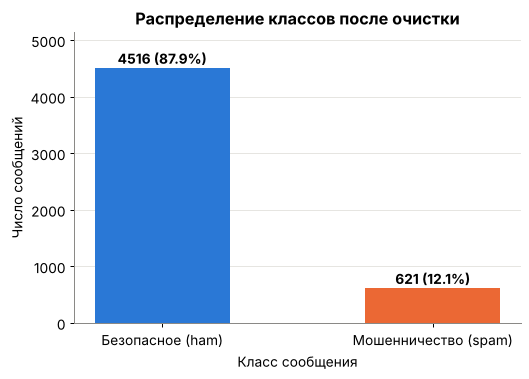

In [2]:
counts = df["label"].value_counts().sort_index()
shares = counts / counts.sum()

fig, ax = plt.subplots(figsize=(6.4, 4.2))
bars = ax.bar([NAMES[i] for i in counts.index], counts.values, width=0.5,
              color=[COLORS[i] for i in counts.index])
for bar, count, share in zip(bars, counts.values, shares.values):
    ax.text(bar.get_x() + bar.get_width() / 2, count + 70, f"{count} ({share:.1%})",
            ha="center", fontweight="bold")
ax.set_title("Распределение классов после очистки")
ax.set_xlabel("Класс сообщения")
ax.set_ylabel("Число сообщений")
ax.set_ylim(0, counts.max() * 1.14)
ax.grid(axis="x", visible=False)
save(fig, "01_class_distribution.png")
plt.show()

print(f"Соотношение ham к spam: {counts[0] / counts[1]:.1f} к 1")

## 2. Длина сообщений по классам

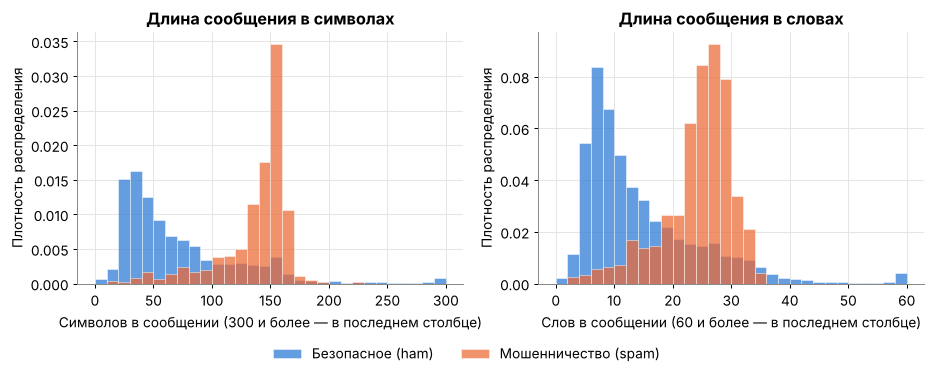

length_chars        length_words       
                             mean median         mean median
Безопасное (ham)             70.9   53.0         14.2   11.0
Мошенничество (spam)        137.6  148.0         23.8   25.0

In [3]:
df["length_chars"] = df["text_raw"].str.len()
df["length_words"] = df["text_raw"].str.split().str.len()

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2))
for ax, column, title, xlabel, limit, step in [
    (axes[0], "length_chars", "Длина сообщения в символах", "Символов в сообщении (300 и более — в последнем столбце)", 300, 10),
    (axes[1], "length_words", "Длина сообщения в словах", "Слов в сообщении (60 и более — в последнем столбце)", 60, 2),
]:
    bins = range(0, limit + step, step)
    for label in (0, 1):
        ax.hist(df.loc[df["label"] == label, column].clip(upper=limit), bins=bins, density=True,
                alpha=0.72, color=COLORS[label], label=NAMES[label], edgecolor="white", linewidth=0.5)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Плотность распределения")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2, frameon=False)
fig.tight_layout(rect=(0, 0.07, 1, 1))
save(fig, "02_length_by_class.png")
plt.show()

length_table = df.groupby("label")[["length_chars", "length_words"]].agg(["mean", "median"]).round(1)
length_table.index = [NAMES[i] for i in length_table.index]
length_table

## 3. Топ-20 слов и биграмм по классам (без стоп-слов)

В списке слов служебные токены (`<url>`, `<num>` и другие) пропущены: их доля разобрана отдельно в пункте 4. В биграммах токены оставлены, потому что сочетание вроде `call <phone>` само по себе показательно.

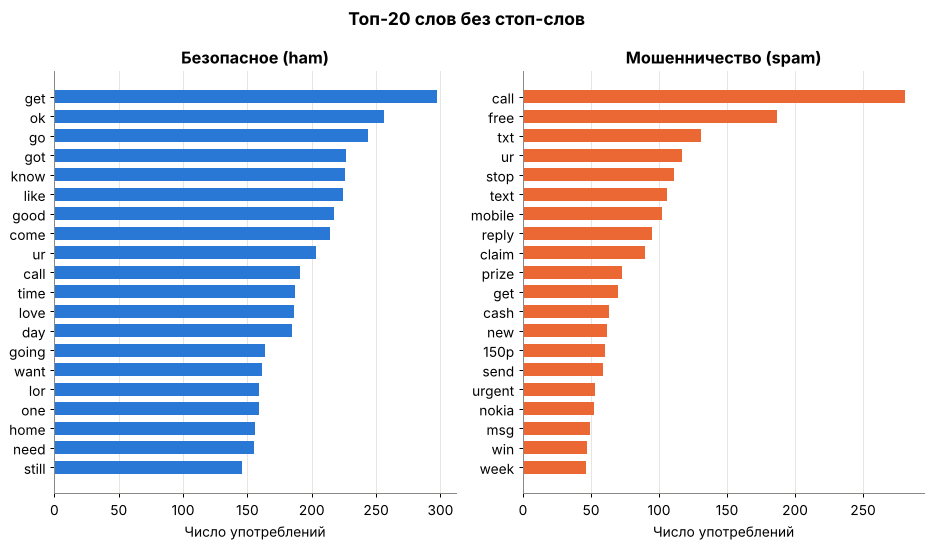

In [4]:
TOKEN = re.compile(r"<\w+>|\w\w+")


def tokens(text):
    return [token for token in TOKEN.findall(text) if token not in STOPWORDS]


def top_terms(label, n_gram, n=20):
    counter = Counter()
    for text in df.loc[df["label"] == label, "text_clean"]:
        items = tokens(text)
        if n_gram == 1:
            counter.update(item for item in items if not item.startswith("<"))
        else:
            counter.update(" ".join(pair) for pair in zip(items, items[1:]))
    return counter.most_common(n)


def plot_top(n_gram, title, name):
    fig, axes = plt.subplots(1, 2, figsize=(10.5, 6.2))
    for ax, label in zip(axes, (0, 1)):
        terms = top_terms(label, n_gram)[::-1]
        ax.barh([term for term, _ in terms], [count for _, count in terms], color=COLORS[label], height=0.68)
        ax.set_title(NAMES[label])
        ax.set_xlabel("Число употреблений")
        ax.grid(axis="y", visible=False)
    fig.suptitle(title, fontweight="bold", fontsize=14)
    fig.tight_layout()
    save(fig, name)
    plt.show()


plot_top(1, "Топ-20 слов без стоп-слов", "03_top_words.png")

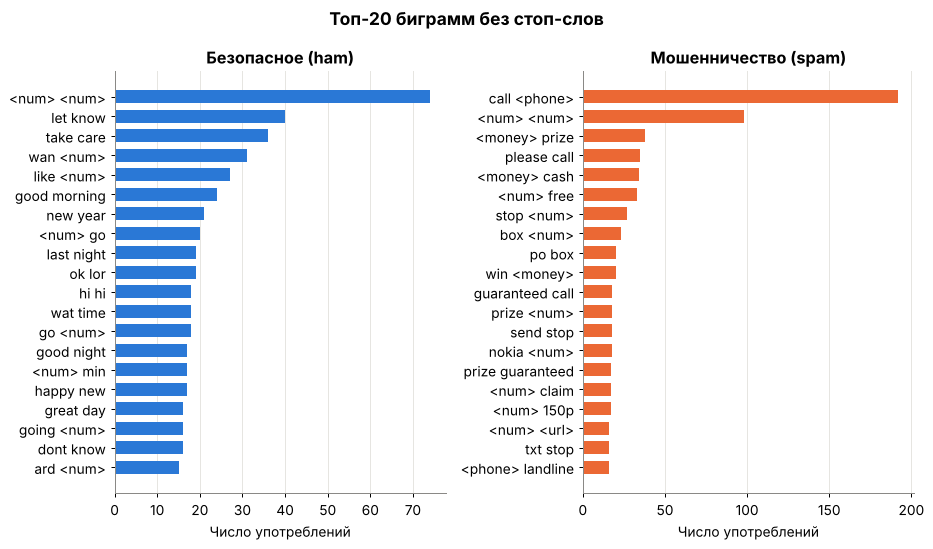

In [5]:
plot_top(2, "Топ-20 биграмм без стоп-слов", "04_top_bigrams.png")

## 4. Доля сообщений с токенами `<url>`, `<phone>`, `<money>`, `!`

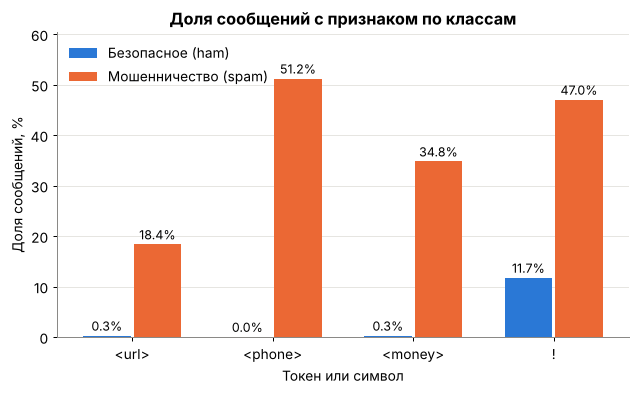

,Безопасное (ham),Мошенничество (spam)
<url>,0.3,18.4
<phone>,0.0,51.2
<money>,0.3,34.8
!,11.7,47.0


In [6]:
MARKS = {"<url>": "<url>", "<phone>": "<phone>", "<money>": "<money>", "!": " ! "}
share_table = pd.DataFrame({
    NAMES[label]: {
        mark: (" " + group["text_clean"] + " ").str.contains(pattern, regex=False).mean()
        for mark, pattern in MARKS.items()
    }
    for label, group in df.groupby("label")
})

fig, ax = plt.subplots(figsize=(8.2, 4.4))
positions = range(len(share_table))
width = 0.36
for offset, label in ((-width / 2, 0), (width / 2, 1)):
    values = share_table[NAMES[label]].values
    bars = ax.bar([p + offset for p in positions], values * 100, width=width - 0.02,
                  color=COLORS[label], label=NAMES[label])
    for bar, value in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width() / 2, value * 100 + 1, f"{value:.1%}", ha="center", fontsize=10)
ax.set_xticks(list(positions), share_table.index)
ax.set_title("Доля сообщений с признаком по классам")
ax.set_xlabel("Токен или символ")
ax.set_ylabel("Доля сообщений, %")
ax.set_ylim(0, share_table.values.max() * 118)
ax.grid(axis="x", visible=False)
ax.legend(frameon=False)
save(fig, "05_token_share.png")
plt.show()

(share_table * 100).round(1)

## 5. Проверка выводов числами

In [7]:
ham, spam = df[df["label"] == 0], df[df["label"] == 1]
upper_share = df["text_raw"].map(lambda t: sum(c.isupper() for c in t) / max(sum(c.isalpha() for c in t), 1))

facts = {
    "средняя длина ham, символов": round(ham["length_chars"].mean(), 1),
    "средняя длина spam, символов": round(spam["length_chars"].mean(), 1),
    "медиана ham, символов": ham["length_chars"].median(),
    "медиана spam, символов": spam["length_chars"].median(),
    "средняя длина ham, слов": round(ham["length_words"].mean(), 1),
    "средняя длина spam, слов": round(spam["length_words"].mean(), 1),
    "spam длиннее 100 символов, %": round((spam["length_chars"] > 100).mean() * 100, 1),
    "ham длиннее 100 символов, %": round((ham["length_chars"] > 100).mean() * 100, 1),
    "доля заглавных ham, %": round(upper_share[df["label"] == 0].mean() * 100, 1),
    "доля заглавных spam, %": round(upper_share[df["label"] == 1].mean() * 100, 1),
    "ham с <phone>, сообщений": int(ham["text_clean"].str.contains("<phone>", regex=False).sum()),
    "spam с <phone>, сообщений": int(spam["text_clean"].str.contains("<phone>", regex=False).sum()),
    "биграмма call <phone> в spam": dict(top_terms(1, 2)).get("call <phone>"),
    "spam без <url>, %": round((~spam["text_clean"].str.contains("<url>", regex=False)).mean() * 100, 1),
    "spam: топ-5 слов": [term for term, _ in top_terms(1, 1, 5)],
    "ham: топ-5 слов": [term for term, _ in top_terms(0, 1, 5)],
}
for name, value in facts.items():
    print(f"{name}: {value}")

средняя длина ham, символов: 70.9
средняя длина spam, символов: 137.6
медиана ham, символов: 53.0
медиана spam, символов: 148.0
средняя длина ham, слов: 14.2
средняя длина spam, слов: 23.8
spam длиннее 100 символов, %: 88.7
ham длиннее 100 символов, %: 22.1
доля заглавных ham, %: 7.7
доля заглавных spam, %: 16.6
ham с <phone>, сообщений: 1
spam с <phone>, сообщений: 318
биграмма call <phone> в spam: 192
spam без <url>, %: 81.6
spam: топ-5 слов: ['call', 'free', 'txt', 'ur', 'stop']
ham: топ-5 слов: ['get', 'ok', 'go', 'got', 'know']


## 6. Выводы

1. **Классы несбалансированы:** 4 516 безопасных (87,9%) против 621 мошеннического (12,1%), соотношение 7,3 к 1. Модель, которая всегда отвечает «безопасное», получит Accuracy 87,9% и не найдёт ни одного мошенничества.
2. **Мошеннические SMS почти вдвое длиннее:** в среднем 137,6 символа против 70,9, медиана 148 против 53. Длиннее 100 символов 88,7% spam и только 22,1% ham. По словам то же: 23,8 против 14,2.
3. **Ссылка редка в безопасных сообщениях, но её нет в большинстве мошеннических:** `<url>` есть в 18,4% spam и в 0,3% ham. При этом 81,6% spam не содержат ссылки, поэтому без анализа текста система пропустила бы такие сообщения.
4. **Сумма денег — сильный признак:** `<money>` есть в 34,8% spam и в 0,3% ham.
5. **Давление заметно в оформлении:** `!` встречается в 47,0% spam и в 11,7% ham, средняя доля заглавных букв 16,6% против 7,7%.
6. **Телефон почти идеально делит классы, и это опасно:** `<phone>` есть у 318 spam (51,2%) и только у 1 ham. Причина, вероятно, не только в мошенничестве: в корпусах безопасных сообщений личные номера обычно скрывают. В реальной работе обычный номер в сообщении может вызвать ложную тревогу, поэтому этот признак надо проверить при разборе ошибок.
7. **Лексика отражает схемы набора:** топ слов spam — `call`, `free`, `txt`, `ur`, `stop`, самая частая биграмма `call <phone>` (192 раза), далее `<money> prize`. В ham топ составляют `get`, `ok`, `go`, `got`, `know`. Многие слова связаны с британскими платными рассылками, поэтому на других языках и в других схемах модель будет работать хуже.

## 7. Как будет учтён дисбаланс

- **Разбиение:** стратифицированное, доля spam одинакова в обучении, валидации и тесте.
- **Обучение:** `class_weight='balanced'` в Logistic Regression увеличивает вес редкого класса.
- **Метрики:** Accuracy не используется для выбора модели. Главные метрики — Recall, Precision и F1 для класса «мошенничество», далее F2 и PR-AUC.

## 8. Гипотезы для признаков

- Длина, доля заглавных букв и число `!` дают сигнал, поэтому войдут в ручные признаки.
- Токены `<url>` и `<money>` стоит сохранить как отдельные признаки.
- Символьные N-граммы нужны для сленга и искажений (`txt`, `ur`, `fr33`).